In [1]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_v2 import Moire
import utils

In [2]:
sys = Moire(theta_deg=1.0, psi_deg=26.0, V=6.6, n_shells=10)

## <span style="color:green">Wannier spread</span>

#### To determine the spread of numerically obtained Wannier functions we will make simulations in the range of $1.0^\circ-2.0^\circ$. As twist angle increases, the Moiré length scale $a_M\sim 1/\theta$ decreases and the Wannier function spread $$\langle r_w^2\rangle = \int d^2\mathbf{r}\; r^2|w(\mathbf{r})|^2$$ is less localized with respect to $a_M$. We will assume that due to symmetry $\langle r_w\rangle = 0$ and therefore the localization functional for a single band is $$\Omega=\langle r_w^2\rangle.$$ We will numerically integrate this quantity in the region $x,y\in[-6a_M,6a_M]\times [-6a_M,6a_M]$ with varying grid resolution $N_x\times N_y$. When constructing Wannier functions we keep a $15\times 15$ mesh of the reciprocal lattice unit cell fixed.

Norm of Wannier function:  0.9999999388913022 | theta = 0.5
Norm of Wannier function:  0.999999999984561 | theta = 1.0
Norm of Wannier function:  0.9999999512839451 | theta = 2.0


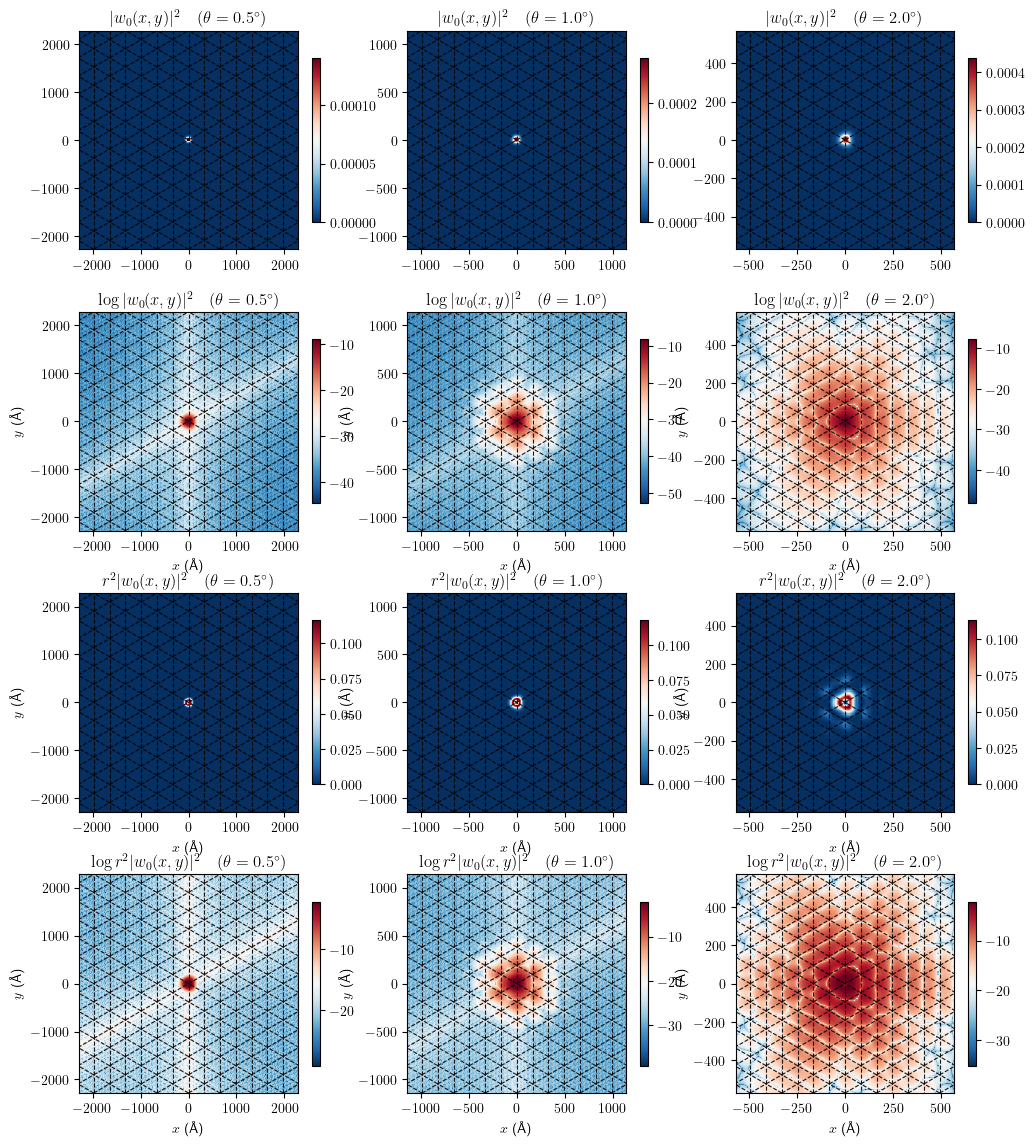

In [ ]:
scale = 6.0

Nx = 200
Ny = 200

thetas = [0.5, 1.0, 2.0]

fig, ax = plt.subplots(4, len(thetas), figsize=(12, 14))

for i in range(len(thetas)):
    sys.theta_deg = thetas[i]
    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)

    k_points = sys.mesh_k_unit_cell(Nx=20, Ny=20)
    im = sys.plot_wannier_function(ax[0, i], X, Y, k_points)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    sys.plot_triangular_lattice(ax[0, i], extent)
    ax[0, i].set_title(r'$|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');
    cbar = fig.colorbar(im, ax=ax[0,i], shrink=0.7)

    wannier = sys.wannier_wavefunction(X, Y, k_points, gauge_fixed=True)
    fun = lambda x, y: 1
    print("Norm of Wannier function: ", sys.integrate_wannier(fun, X, Y, k_points), "| theta =", thetas[i])
    density = np.abs(wannier)**2

    im = ax[1, i].imshow(np.log(density), extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')
    cbar = fig.colorbar(im, ax=ax[1, i], shrink=0.7)

    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    sys.plot_triangular_lattice(ax[1, i], extent)

    ax[1, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[1, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[1, i].set_title(r'$\log|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

    R2 = X**2 + Y**2
    im = ax[2, i].imshow(R2 * density, extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')
    cbar = fig.colorbar(im, ax=ax[2, i], shrink=0.7)

    sys.plot_triangular_lattice(ax[2, i], extent)

    ax[2, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[2, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[2, i].set_title(r'$r^2|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');
    
    im = ax[3, i].imshow(np.log(R2 * density), extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')
    cbar = fig.colorbar(im, ax=ax[3, i], shrink=0.7)

    sys.plot_triangular_lattice(ax[3, i], extent)

    ax[3, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[3, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[3, i].set_title(r'$\log r^2|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

## <span style="color:red">Trace of Metric</span>

#### The gauge independent part $\Omega_I$ of the localization functional $\Omega = \Omega_I + \tilde{\Omega}$ is given in terms of the quantum metric $g(\mathbf{k})$ as $$\Omega_I = \frac{1}{A_{BZ}}\int d^2\mathbf{k}\; \text{Tr}(g(\mathbf{k})).$$ It gives us a lower bound to the spread of the gauge-dependent Wannier function. Here we calculate the metric $g_{\alpha \beta}=[Q_{\alpha \beta}+Q_{\beta\alpha}]/2$ as the symmetric part of the Quantum Geometric Tensor (QGT) $$Q_{\alpha \beta}(\mathbf{k})=\langle D_\alpha u_{\mathbf{k}}| D_\beta u_{\mathbf{k}}\rangle.$$ We set the directions $\alpha$ and $\beta$ parallel to reciprocal lattice basis vectors $$b_\alpha = \begin{pmatrix} \frac{4\pi}{\sqrt{3}a_M}\\0\end{pmatrix},\quad\quad b_\beta = \begin{pmatrix} -\frac{2\pi}{\sqrt{3}a_M}\\\frac{2\pi}{a_M}\end{pmatrix}.$$

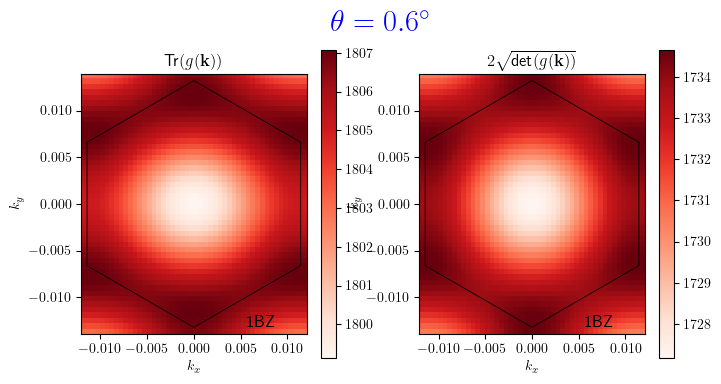

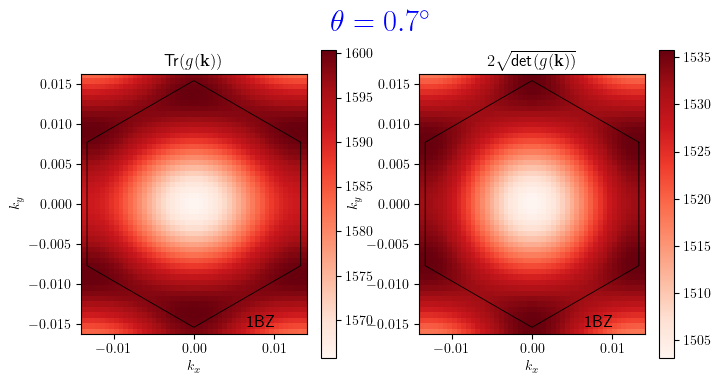

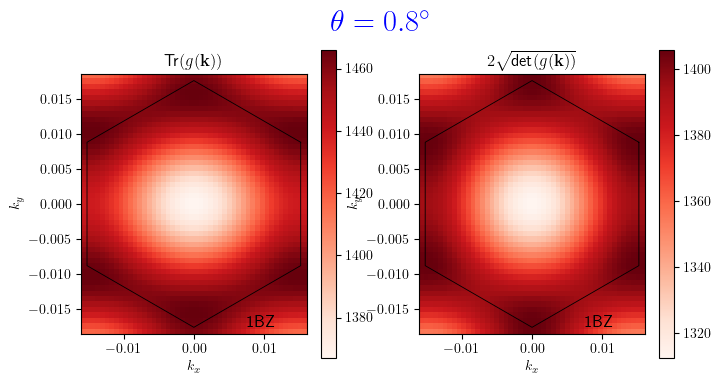

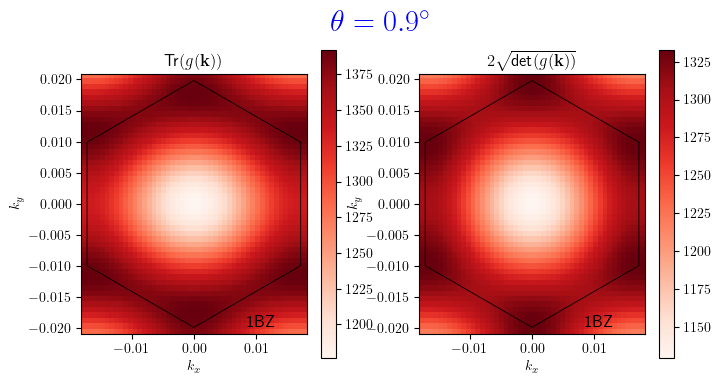

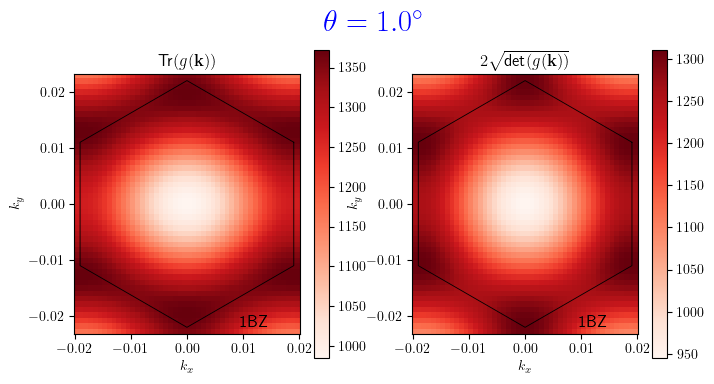

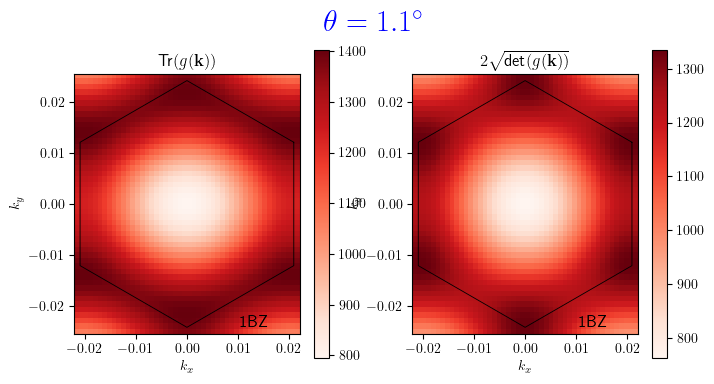

In [28]:
sys.theta_deg = 0.6

for _ in range(6):
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    scale = 1.1
    kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
    ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
    KX, KY = np.meshgrid(kx, ky)
    sys.plot_trace_metric(ax, KX, KY)

    plt.xlabel(r'$k_x$')
    plt.ylabel(r'$k_y$')
    plt.suptitle(r'$\theta = %.1f^\circ$' % sys.theta_deg, fontsize=22, color='blue')
    sys.theta_deg += 0.1

## <span style="color:blue">Method 1</span>

#### We do a triangular mesh of $k-$ space in order to calculate derivatives in directions $\alpha$ and $\beta$. To estimate the integral, we only count valid points we obtain by mapping points in a single unit cell to the BZ.

Figure(1000x500)


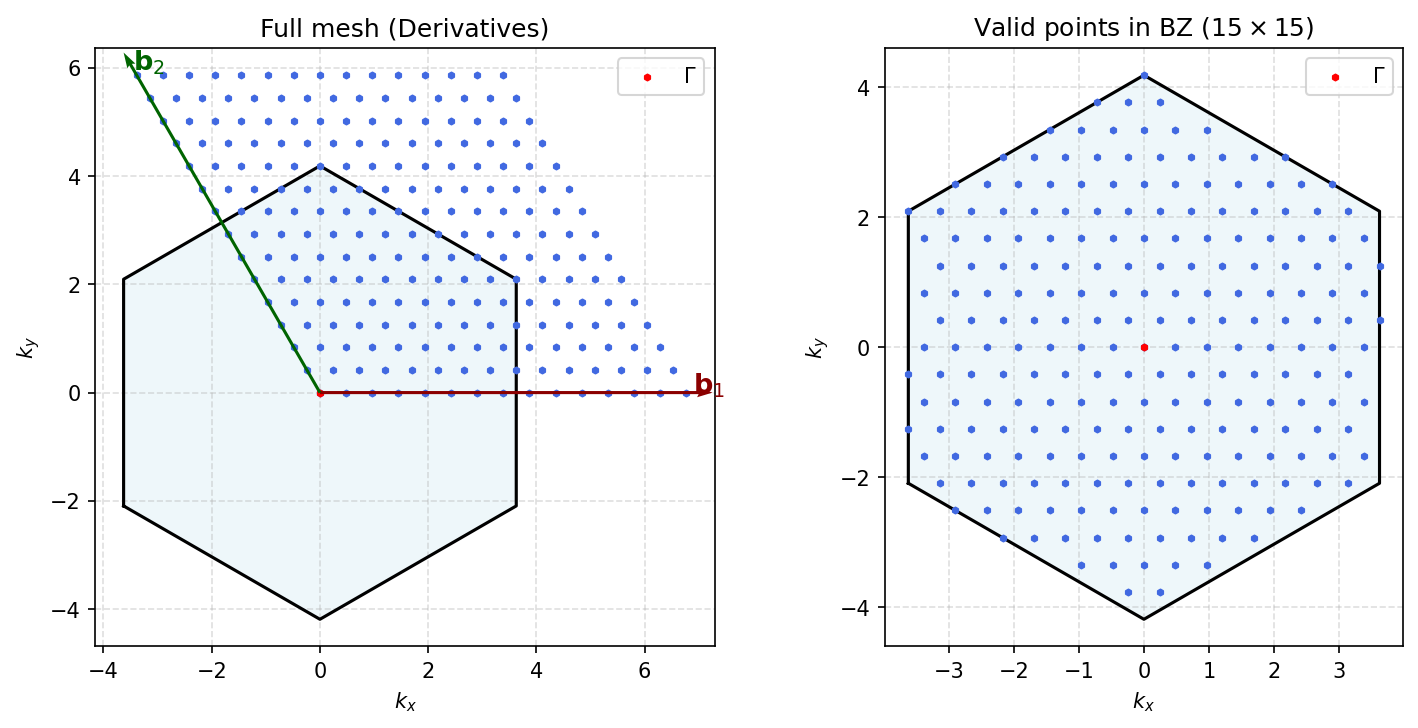

In [5]:
!python ~/Desktop/UniStuttgart/flatiron/project/flatiron/diagonalization//src/mesh.py

from IPython.display import Image
Image('bz_mesh.png')

In [6]:
thetas = np.linspace(1.0, 2.0, 20)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
rW_values = []
l0_valuesH = []
scale_W = 6.0

NxR = 100
NyR = 100

NxK = 15
NyK = 15

for th in tqdm(thetas):
    sys.theta_deg = th

    x = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, NxR)
    y = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, NyR)
    X, Y = np.meshgrid(x, y)
    k_points = sys.mesh_k_unit_cell(Nx=NxK, Ny=NyK)

    fun = lambda xx, yy: xx**2 + yy**2
    rW = np.sqrt( sys.integrate_wannier(fun, X, Y, k_points) )
    rW_values.append(rW)

    k_points, k_in_bz, shape, dkx, dky = sys.mesh_k_hex(Nx=NxK, Ny=NyK)

    _, integral = sys.integrate_trace_hex(k_points, k_in_bz, shape, dkx, dky, shift="infinitesimal")
    l0 = np.sqrt(integral)
    l0_valuesH.append(l0)

100%|██████████| 20/20 [03:16<00:00,  9.85s/it]


<>:11: SyntaxWarning: invalid escape sequence '\p'
<>:11: SyntaxWarning: invalid escape sequence '\c'
<>:11: SyntaxWarning: invalid escape sequence '\p'
<>:11: SyntaxWarning: invalid escape sequence '\c'
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_2422/3637569261.py:11: SyntaxWarning: invalid escape sequence '\p'
  plt.text(1.7, 0.15, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_2422/3637569261.py:11: SyntaxWarning: invalid escape sequence '\c'
  plt.text(1.7, 0.15, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);


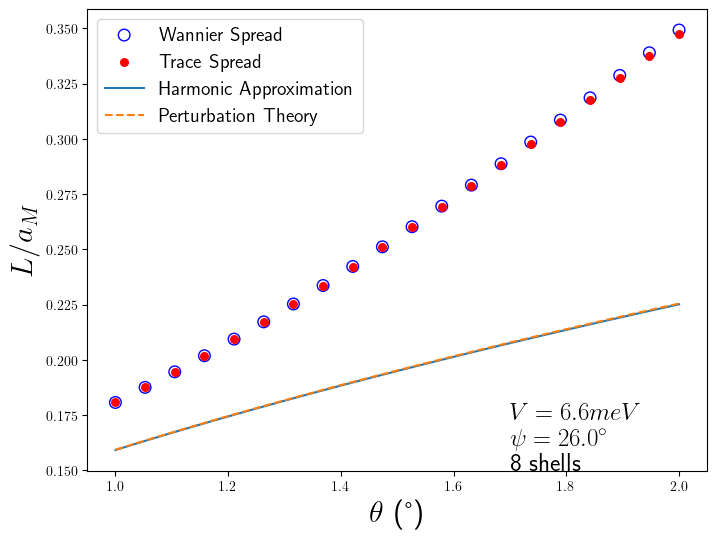

In [7]:
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

fig = plt.figure(figsize=(8, 6))
plt.scatter(thetas, np.array(rW_values) / aMs0, facecolors='none', edgecolors='blue', s=70, label='Wannier Spread')
plt.scatter(thetas, np.array(l0_valuesH) / aMs0, facecolors='red', edgecolors='red', s=30, label='Trace Spread')
plt.plot(thetas2, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs, label='Harmonic Approximation')
plt.plot(thetas2, utils.spread_perturbation(aMs, sys.V, sys.psi) / aMs, '--', label='Perturbation Theory')
plt.xlabel(r'$\theta$ (°)', fontsize=22)
plt.ylabel(r'$L / a_M$', fontsize=22)
plt.text(1.7, 0.15, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
plt.legend(fontsize=14)
plt.show()

0it [00:00, ?it/s]

4it [04:00, 60.02s/it]


(0.0, 1.0)

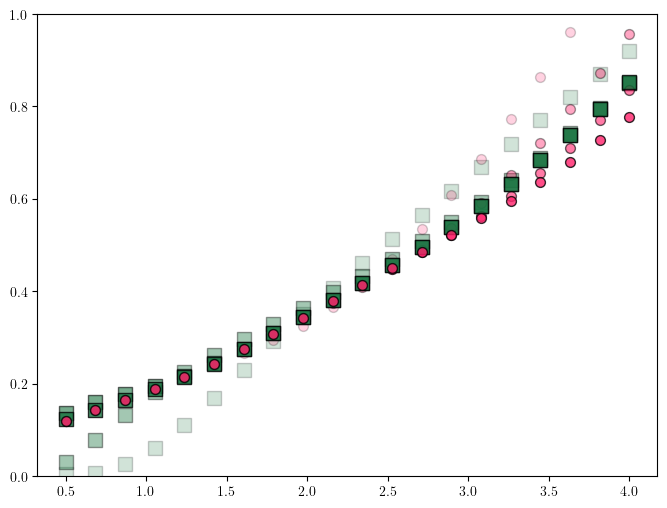

In [18]:
sys.n_shells = 10
sys.psi_deg = 26.0
sys.V = 6.6

thetas = np.linspace(0.5, 4.0, 20)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

scale_W = 12.0

NxR = 100
NyR = 100

NxK = 21
NyK = 21

k_res = [3, 6, 9, 12]
k_alpha = [0.2, 0.4, 0.6, 0.8]
x_res = [30, 50, 100, 150]
x_alpha = [0.2, 0.4, 0.6, 0.8]

fig, ax = plt.subplots(figsize=(8, 6))

for resx, resk, alphax, alphak in tqdm(zip(x_res, k_res, x_alpha, k_alpha)):
    rW_values = []
    l0_valuesH = []

    for th in thetas:
        sys.theta_deg = th

        x = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, resx)
        y = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, resx)
        X, Y = np.meshgrid(x, y)
        k_points = sys.mesh_k_unit_cell(Nx=NxK, Ny=NyK)

        fun = lambda xx, yy: xx**2 + yy**2
        rW = np.sqrt(sys.integrate_wannier(fun, X, Y, k_points))
        rW_values.append(rW)

        integral = sys.integrate_trace(Nx=resk, Ny=resk)
        l0 = np.sqrt(integral)
        l0_valuesH.append(l0)

    ax.scatter(thetas, np.array(rW_values) / aMs0, facecolors='#197340', edgecolors='k',
                   s=100, marker='s', alpha=alphax)
    ax.scatter(thetas, np.array(l0_valuesH) / aMs0, facecolors='#FF216B', edgecolors='k',
                s=50, alpha=alphak)
ax.set_ylim([0, 1])

V=6.6: 1it [00:06,  6.16s/it]


KeyboardInterrupt: 

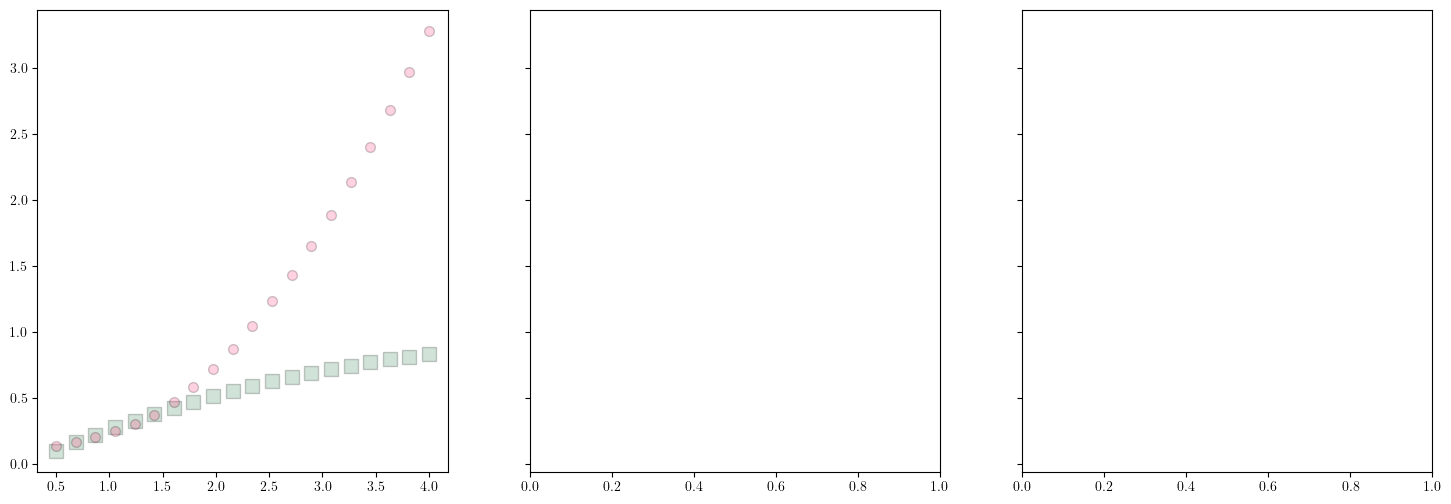

In [7]:
sys.n_shells = 8
sys.psi_deg = 50.0
thetas = np.linspace(0.5, 4.0, 20)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

scale_W = 6.0

NxR = 100
NyR = 100

NxK = 15
NyK = 15

k_res = [3, 6, 9, 12]
k_alpha = [0.2, 0.4, 0.6, 0.8]
x_res = [30, 50, 100, 150]
x_alpha = [0.2, 0.4, 0.6, 0.8]

V_values = [6.6, 15, 30]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for ax, V in zip(axes, V_values):
    sys.V = V

    for resx, resk, alphax, alphak in tqdm(zip(x_res, k_res, x_alpha, k_alpha), desc=f"V={V}"):
        rW_values = []
        l0_valuesH = []
        for th in thetas:
            sys.theta_deg = th

            x = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, resx)
            y = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, resx)
            X, Y = np.meshgrid(x, y)
            k_points = sys.mesh_k_unit_cell(Nx=15, Ny=15)

            fun = lambda xx, yy: xx**2 + yy**2
            rW = np.sqrt(sys.integrate_wannier(fun, X, Y, k_points))
            rW_values.append(rW)

            integral = sys.integrate_trace(Nx=resk, Ny=resk)
            l0 = np.sqrt(integral)
            l0_valuesH.append(l0)

        ax.scatter(thetas, np.array(rW_values) / aMs0, facecolors='#197340', edgecolors='k',
                   s=100, marker='s', alpha=alphax)
        ax.scatter(thetas, np.array(l0_valuesH) / aMs0, facecolors='#FF216B', edgecolors='k',
                   s=50, alpha=alphak)

    ax.plot(thetas2, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs,
            label='Harmonic Approximation', color='#3794BA', linewidth=3)
    ax.plot(thetas2, utils.spread_perturbation(aMs, sys.V, sys.psi) / aMs, '--',
            label='Perturbation Theory', color='k', linewidth=2)

    # --- Resolution legends (only on the first subplot to avoid clutter) ---
    if ax == axes[0]:
        legend_x_handles = [
            Line2D([0], [0], marker='s', color='w', label=rf'${resx} \times {resx}$',
                   markerfacecolor='#197340', markeredgecolor='k',
                   markersize=10, alpha=alphax)
            for resx, alphax in zip(x_res, x_alpha)
        ]
        legend_k_handles = [
            Line2D([0], [0], marker='o', color='w', label=rf'${resk} \times {resk}$',
                   markerfacecolor='#FF216B', markeredgecolor='k',
                   markersize=8, alpha=alphak)
            for resk, alphak in zip(k_res, k_alpha)
        ]

        # leg_x = ax.legend(handles=legend_x_handles, title=r'$x-$Grid',
        #                   fontsize=10, title_fontsize=10, loc='upper left')
        # leg_k = ax.legend(handles=legend_k_handles, title=r'$k-$Grid',
        #                   fontsize=10, title_fontsize=10, loc='center right')
        # ax.add_artist(leg_x)
        leg_x = ax.legend(handles=legend_x_handles, title=r'$x-$Grid (Wannier)',
                  fontsize=10, title_fontsize=10,
                  loc='upper left', bbox_to_anchor=(0, 1))
        leg_k = ax.legend(handles=legend_k_handles, title=r'$k-$Grid (Trace)',
                        fontsize=10, title_fontsize=10,
                        loc='upper left', bbox_to_anchor=(0.24, 1))
        ax.add_artist(leg_x)
        plt.savefig("plots/spread_vs_theta.pdf", dpi=300, bbox_inches='tight')

    # --- Line legend on every subplot ---
    leg_lines = ax.legend(handles=[
        Line2D([0], [0], color='#3794BA', linewidth=3, label='Harmonic Approximation'),
        Line2D([0], [0], color='k', linewidth=2, linestyle='dotted', label='Perturbation Theory'),
    ], fontsize=10, loc='lower right')

    if ax == axes[0]:
        ax.add_artist(leg_k)

    ax.set_title(rf"$V = {V}\ \mathrm{{meV}}$, $\psi = {sys.psi_deg}\ ^\circ$", fontsize=20)
    ax.set_xlabel(r'$\theta$ (°)', fontsize=20)
    #ax.set_ylim([.12, .38])

axes[0].set_ylabel(r'$L / a_M$', fontsize=20)

plt.tight_layout()
plt.savefig("plots/spread_vs_theta.pdf", dpi=300, bbox_inches='tight')
plt.show()

4it [02:40, 40.05s/it]
4it [02:46, 41.53s/it]
4it [03:02, 45.65s/it]


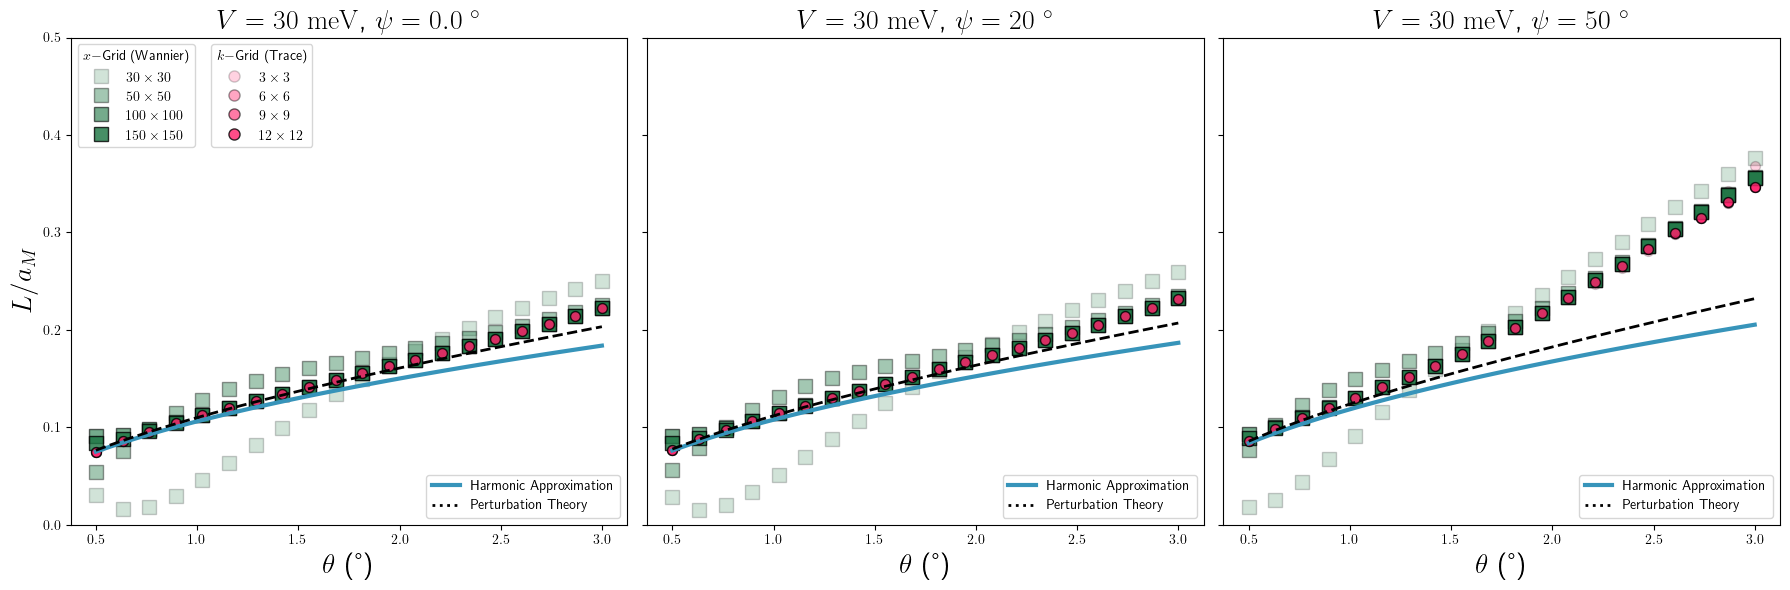

In [7]:
sys.n_shells = 12
thetas = np.linspace(0.5, 3.0, 20)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

scale_W = 6.0

NxR = 100
NyR = 100

NxK = 15
NyK = 15

k_res = [3, 6, 9, 12]
k_alpha = [0.2, 0.4, 0.6, 0.8]
x_res = [30, 50, 100, 150]
x_alpha = [0.2, 0.4, 0.6, 0.8]

psi_values = [0.0, 20, 50]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for ax, psi in zip(axes, psi_values):
    sys.psi_deg = psi

    for resx, resk, alphax, alphak in tqdm(zip(x_res, k_res, x_alpha, k_alpha)):
        rW_values = []
        l0_valuesH = []
        for th in thetas:
            sys.theta_deg = th

            x = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, resx)
            y = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, resx)
            X, Y = np.meshgrid(x, y)
            k_points = sys.mesh_k_unit_cell(Nx=15, Ny=15)

            fun = lambda xx, yy: xx**2 + yy**2
            rW = np.sqrt(sys.integrate_wannier(fun, X, Y, k_points))
            rW_values.append(rW)

            integral = sys.integrate_trace(Nx=resk, Ny=resk)
            l0 = np.sqrt(integral)
            l0_valuesH.append(l0)

        ax.scatter(thetas, np.array(rW_values) / aMs0, facecolors='#197340', edgecolors='k',
                   s=100, marker='s', alpha=alphax)
        ax.scatter(thetas, np.array(l0_valuesH) / aMs0, facecolors='#FF216B', edgecolors='k',
                   s=50, alpha=alphak)

    ax.plot(thetas2, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs,
            label='Harmonic Approximation', color='#3794BA', linewidth=3)
    ax.plot(thetas2, utils.spread_perturbation(aMs, sys.V, sys.psi) / aMs, '--',
            label='Perturbation Theory', color='k', linewidth=2)

    # --- Resolution legends (only on the first subplot to avoid clutter) ---
    if ax == axes[0]:
        legend_x_handles = [
            Line2D([0], [0], marker='s', color='w', label=rf'${resx} \times {resx}$',
                   markerfacecolor='#197340', markeredgecolor='k',
                   markersize=10, alpha=alphax)
            for resx, alphax in zip(x_res, x_alpha)
        ]
        legend_k_handles = [
            Line2D([0], [0], marker='o', color='w', label=rf'${resk} \times {resk}$',
                   markerfacecolor='#FF216B', markeredgecolor='k',
                   markersize=8, alpha=alphak)
            for resk, alphak in zip(k_res, k_alpha)
        ]

        # leg_x = ax.legend(handles=legend_x_handles, title=r'$x-$Grid',
        #                   fontsize=10, title_fontsize=10, loc='upper left')
        # leg_k = ax.legend(handles=legend_k_handles, title=r'$k-$Grid',
        #                   fontsize=10, title_fontsize=10, loc='center right')
        # ax.add_artist(leg_x)
        leg_x = ax.legend(handles=legend_x_handles, title=r'$x-$Grid (Wannier)',
                  fontsize=10, title_fontsize=10,
                  loc='upper left', bbox_to_anchor=(0, 1))
        leg_k = ax.legend(handles=legend_k_handles, title=r'$k-$Grid (Trace)',
                        fontsize=10, title_fontsize=10,
                        loc='upper left', bbox_to_anchor=(0.24, 1))
        ax.add_artist(leg_x)
        plt.savefig("plots/spread_vs_theta.pdf", dpi=300, bbox_inches='tight')

    # --- Line legend on every subplot ---
    leg_lines = ax.legend(handles=[
        Line2D([0], [0], color='#3794BA', linewidth=3, label='Harmonic Approximation'),
        Line2D([0], [0], color='k', linewidth=2, linestyle='dotted', label='Perturbation Theory'),
    ], fontsize=10, loc='lower right')

    if ax == axes[0]:
        ax.add_artist(leg_k)

    ax.set_title(rf"$V = {sys.V}\ \mathrm{{meV}}$, $\psi = {sys.psi_deg}\ ^\circ$", fontsize=20)
    ax.set_xlabel(r'$\theta$ (°)', fontsize=20)
    ax.set_ylim([0.0, .5])

axes[0].set_ylabel(r'$L / a_M$', fontsize=20)

plt.tight_layout()
plt.savefig("plots/spread_vs_theta.pdf", dpi=300, bbox_inches='tight')
plt.show()